In [1]:
# # STEP 01.9 — Label and Class Distribution Validation

# ## Objective

# Validate ASD and NON-ASD label distributions across Genetic,
# Behavioral, and Environmental modalities.

# This analysis operates at the knowledge and class level.

# Patient-level matching is NOT used because the three modalities
# contain different individuals.

# Key Questions:
# - Are labels valid?
# - What is the class distribution per modality?
# - How severe is class imbalance?
# # - Why is balanced sampling necessary for cross-modal comparison?

In [2]:
# ============================================================
# STEP 01.9 — LABEL AND CLASS DISTRIBUTION VALIDATION
# CELL 2 — IMPORTS AND PROJECT CONFIGURATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

print("=" * 100)
print("STEP 01.9 — LABEL AND CLASS DISTRIBUTION VALIDATION")
print("=" * 100)

# ------------------------------------------------------------
# Project Root
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening"
)

# ------------------------------------------------------------
# Output Directories
# ------------------------------------------------------------

REPORT_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "reports"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "figures"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("\nProject Root:")
print(PROJECT_ROOT)

print("\n✓ Initialization completed")

STEP 01.9 — LABEL AND CLASS DISTRIBUTION VALIDATION

Project Root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

✓ Initialization completed


In [4]:
# ============================================================
# CELL 3 — LOCATE AND LOAD FROZEN TARGET LABELS
# ============================================================

import numpy as np
from pathlib import Path

print("=" * 100)
print("STEP 01.9 — LOCATING FROZEN TARGET LABELS")
print("=" * 100)

# ------------------------------------------------------------
# Search for the exact target files across the project
# ------------------------------------------------------------

genetic_matches = list(PROJECT_ROOT.rglob("genetic_targets.npy"))
behavioral_matches = list(PROJECT_ROOT.rglob("behavioral_targets.npy"))
environmental_matches = list(PROJECT_ROOT.rglob("environmental_targets.npy"))

print("\nGENETIC TARGET FILES FOUND:")
for path in genetic_matches:
    print(path)

print("\nBEHAVIORAL TARGET FILES FOUND:")
for path in behavioral_matches:
    print(path)

print("\nENVIRONMENTAL TARGET FILES FOUND:")
for path in environmental_matches:
    print(path)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

if not genetic_matches:
    raise FileNotFoundError("genetic_targets.npy was not found anywhere in PROJECT_ROOT")

if not behavioral_matches:
    raise FileNotFoundError("behavioral_targets.npy was not found anywhere in PROJECT_ROOT")

if not environmental_matches:
    raise FileNotFoundError("environmental_targets.npy was not found anywhere in PROJECT_ROOT")

# ------------------------------------------------------------
# Select first matching frozen baseline artifact
# ------------------------------------------------------------

GENETIC_TARGET_PATH = genetic_matches[0]
BEHAVIORAL_TARGET_PATH = behavioral_matches[0]
ENVIRONMENTAL_TARGET_PATH = environmental_matches[0]

# ------------------------------------------------------------
# Load targets
# ------------------------------------------------------------

genetic_labels = np.load(GENETIC_TARGET_PATH)
behavioral_labels = np.load(BEHAVIORAL_TARGET_PATH)
environmental_labels = np.load(ENVIRONMENTAL_TARGET_PATH)

print("\n" + "=" * 100)
print("TARGET LABELS LOADED SUCCESSFULLY")
print("=" * 100)

print(f"\nGenetic path       : {GENETIC_TARGET_PATH}")
print(f"Genetic shape      : {genetic_labels.shape}")
print(f"Genetic classes    : {np.unique(genetic_labels)}")

print(f"\nBehavioral path    : {BEHAVIORAL_TARGET_PATH}")
print(f"Behavioral shape   : {behavioral_labels.shape}")
print(f"Behavioral classes : {np.unique(behavioral_labels)}")

print(f"\nEnvironmental path : {ENVIRONMENTAL_TARGET_PATH}")
print(f"Environmental shape: {environmental_labels.shape}")
print(f"Environmental classes: {np.unique(environmental_labels)}")

print("\n✓ Frozen baseline labels successfully loaded")

STEP 01.9 — LOCATING FROZEN TARGET LABELS

GENETIC TARGET FILES FOUND:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\05_multimodal_fusion\genetic_targets.npy

BEHAVIORAL TARGET FILES FOUND:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\05_multimodal_fusion\behavioral_targets.npy

ENVIRONMENTAL TARGET FILES FOUND:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\05_multimodal_fusion\environmental_targets.npy

TARGET LABELS LOADED SUCCESSFULLY

Genetic path       : C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\05_multimodal_fusion\genetic_targets.npy
Genetic shape      : (116,)
Genetic classes    : [0 1]

Behavioral path    : C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\05_multimodal_fusion\behavioral_targets.npy
Behavioral shape   : (880,)
Behavioral classes : [0 1]

Environmental path : C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\05_multimodal_

In [6]:
# ============================================================
# CELL 4 — ORIGINAL LABEL AND CLASS DISTRIBUTION VALIDATION
# ============================================================

print("=" * 100)
print("STEP 01.9 — ORIGINAL LABEL AND CLASS DISTRIBUTION VALIDATION")
print("=" * 100)

# ------------------------------------------------------------
# Organize labels by modality
# ------------------------------------------------------------

labels_dict = {
    "Genetic": genetic_labels,
    "Behavioral": behavioral_labels,
    "Environmental": environmental_labels
}

# ------------------------------------------------------------
# Initialize results storage
# ------------------------------------------------------------

validation_results = []

# ------------------------------------------------------------
# Validate each modality
# ------------------------------------------------------------

for modality, labels in labels_dict.items():

    unique_labels = np.unique(labels)

    total_samples = len(labels)

    class_0_count = np.sum(labels == 0)
    class_1_count = np.sum(labels == 1)

    class_0_percentage = (class_0_count / total_samples) * 100
    class_1_percentage = (class_1_count / total_samples) * 100

    is_binary = set(unique_labels).issubset({0, 1})
    has_both_classes = len(unique_labels) == 2
    has_missing_values = np.isnan(labels).any()

    validation_results.append({
        "Modality": modality,
        "Total Samples": total_samples,
        "Unique Labels": list(unique_labels),
        "Class 0 Count": class_0_count,
        "Class 1 Count": class_1_count,
        "Class 0 Percentage": class_0_percentage,
        "Class 1 Percentage": class_1_percentage,
        "Binary Labels": is_binary,
        "Both Classes Present": has_both_classes,
        "Missing Labels": has_missing_values
    })

# ------------------------------------------------------------
# Create validation dataframe
# ------------------------------------------------------------

validation_df = pd.DataFrame(validation_results)

print("\nORIGINAL CLASS DISTRIBUTION")
print("-" * 100)

display(validation_df)

print("\n" + "=" * 100)
print("VALIDATION CHECK")
print("=" * 100)

for _, row in validation_df.iterrows():

    print(f"\n{row['Modality']}")
    print(f"  Total Samples       : {row['Total Samples']}")
    print(f"  Unique Labels       : {row['Unique Labels']}")
    print(f"  Class 0             : {row['Class 0 Count']} ({row['Class 0 Percentage']:.2f}%)")
    print(f"  Class 1             : {row['Class 1 Count']} ({row['Class 1 Percentage']:.2f}%)")
    print(f"  Binary Labels       : {row['Binary Labels']}")
    print(f"  Both Classes Present: {row['Both Classes Present']}")
    print(f"  Missing Labels      : {row['Missing Labels']}")

print("\n✓ Original label distribution validation completed")

STEP 01.9 — ORIGINAL LABEL AND CLASS DISTRIBUTION VALIDATION

ORIGINAL CLASS DISTRIBUTION
----------------------------------------------------------------------------------------------------


,Modality,Total Samples,Unique Labels,Class 0 Count,Class 1 Count,Class 0 Percentage,Class 1 Percentage,Binary Labels,Both Classes Present,Missing Labels
0,Genetic,116,"[0, 1]",29,87,25.000000,75.000000,True,True,False
1,Behavioral,880,"[0, 1]",439,441,49.886364,50.113636,True,True,False
2,Environmental,47768,"[0, 1]",45650,2118,95.566069,4.433931,True,True,False



VALIDATION CHECK

Genetic
  Total Samples       : 116
  Unique Labels       : [np.int64(0), np.int64(1)]
  Class 0             : 29 (25.00%)
  Class 1             : 87 (75.00%)
  Binary Labels       : True
  Both Classes Present: True
  Missing Labels      : False

Behavioral
  Total Samples       : 880
  Unique Labels       : [np.int64(0), np.int64(1)]
  Class 0             : 439 (49.89%)
  Class 1             : 441 (50.11%)
  Binary Labels       : True
  Both Classes Present: True
  Missing Labels      : False

Environmental
  Total Samples       : 47768
  Unique Labels       : [np.int64(0), np.int64(1)]
  Class 0             : 45650 (95.57%)
  Class 1             : 2118 (4.43%)
  Binary Labels       : True
  Both Classes Present: True
  Missing Labels      : False

✓ Original label distribution validation completed


In [7]:
# ============================================================
# CELL 5 — CLASS DISTRIBUTION ANALYSIS
# ============================================================

print("=" * 100)
print("CLASS DISTRIBUTION ANALYSIS")
print("=" * 100)

distribution_results = []

for modality, labels in labels_dict.items():

    total_samples = len(labels)

    class_0_count = np.sum(labels == 0)
    class_1_count = np.sum(labels == 1)

    class_0_percentage = (
        class_0_count / total_samples
    ) * 100

    class_1_percentage = (
        class_1_count / total_samples
    ) * 100

    distribution_results.append({
        "Modality": modality,
        "Total Samples": total_samples,
        "NON-ASD Count (Class 0)": class_0_count,
        "ASD Count (Class 1)": class_1_count,
        "NON-ASD Percentage": round(class_0_percentage, 2),
        "ASD Percentage": round(class_1_percentage, 2)
    })

distribution_df = pd.DataFrame(distribution_results)

print("\nCLASS DISTRIBUTION SUMMARY\n")
print(distribution_df.to_string(index=False))

distribution_path = (
    REPORT_DIR
    / "01_09_class_distribution_summary.csv"
)

distribution_df.to_csv(distribution_path, index=False)

print("\n✓ Class distribution calculated successfully")

CLASS DISTRIBUTION ANALYSIS

CLASS DISTRIBUTION SUMMARY

     Modality  Total Samples  NON-ASD Count (Class 0)  ASD Count (Class 1)  NON-ASD Percentage  ASD Percentage
      Genetic            116                       29                   87               25.00           75.00
   Behavioral            880                      439                  441               49.89           50.11
Environmental          47768                    45650                 2118               95.57            4.43

✓ Class distribution calculated successfully


In [8]:
# ============================================================
# CELL 6 — CLASS IMBALANCE METRICS
# ============================================================

print("=" * 100)
print("CLASS IMBALANCE ANALYSIS")
print("=" * 100)

imbalance_results = []

for modality, labels in labels_dict.items():

    class_counts = np.bincount(labels)

    class_0_count = class_counts[0]
    class_1_count = class_counts[1]

    majority_count = max(class_0_count, class_1_count)
    minority_count = min(class_0_count, class_1_count)

    imbalance_ratio = (
        majority_count / minority_count
        if minority_count > 0
        else np.inf
    )

    minority_percentage = (
        minority_count / len(labels)
    ) * 100

    if imbalance_ratio <= 1.5:
        severity = "Balanced"
    elif imbalance_ratio <= 3:
        severity = "Moderate Imbalance"
    elif imbalance_ratio <= 10:
        severity = "High Imbalance"
    else:
        severity = "Extreme Imbalance"

    imbalance_results.append({
        "Modality": modality,
        "Majority Class Count": majority_count,
        "Minority Class Count": minority_count,
        "Imbalance Ratio": round(imbalance_ratio, 4),
        "Minority Class Percentage": round(minority_percentage, 2),
        "Imbalance Severity": severity
    })

imbalance_df = pd.DataFrame(imbalance_results)

print("\nCLASS IMBALANCE SUMMARY\n")
print(imbalance_df.to_string(index=False))

imbalance_path = (
    REPORT_DIR
    / "01_09_class_imbalance_metrics.csv"
)

imbalance_df.to_csv(imbalance_path, index=False)

print("\n✓ Class imbalance analysis completed")

CLASS IMBALANCE ANALYSIS

CLASS IMBALANCE SUMMARY

     Modality  Majority Class Count  Minority Class Count  Imbalance Ratio  Minority Class Percentage Imbalance Severity
      Genetic                    87                    29           3.0000                      25.00 Moderate Imbalance
   Behavioral                   441                   439           1.0046                      49.89           Balanced
Environmental                 45650                  2118          21.5534                       4.43  Extreme Imbalance

✓ Class imbalance analysis completed


GENERATING RAW CLASS DISTRIBUTION VISUALIZATION


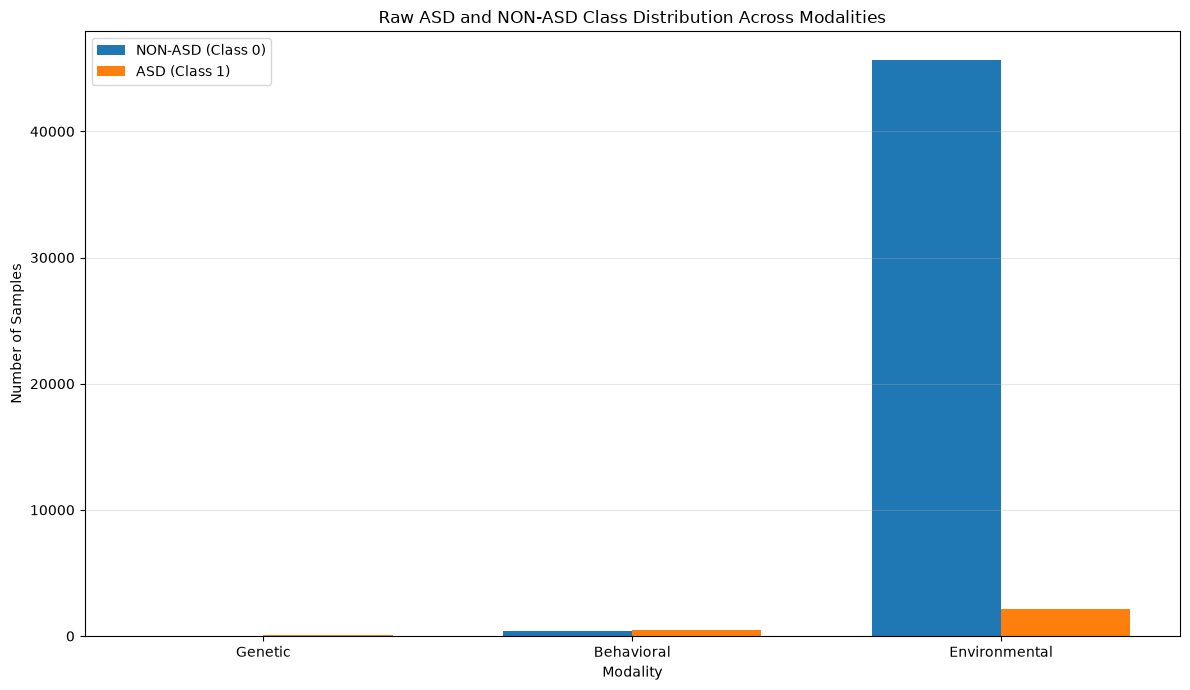


Figure saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_09_raw_class_distribution.png


In [9]:
# ============================================================
# CELL 7 — RAW CLASS DISTRIBUTION VISUALIZATION
# ============================================================

print("=" * 100)
print("GENERATING RAW CLASS DISTRIBUTION VISUALIZATION")
print("=" * 100)

modalities = distribution_df["Modality"].tolist()

non_asd_counts = distribution_df[
    "NON-ASD Count (Class 0)"
].tolist()

asd_counts = distribution_df[
    "ASD Count (Class 1)"
].tolist()

x = np.arange(len(modalities))
width = 0.35

plt.figure(figsize=(12, 7))

plt.bar(
    x - width / 2,
    non_asd_counts,
    width,
    label="NON-ASD (Class 0)"
)

plt.bar(
    x + width / 2,
    asd_counts,
    width,
    label="ASD (Class 1)"
)

plt.xticks(x, modalities)

plt.xlabel("Modality")
plt.ylabel("Number of Samples")

plt.title(
    "Raw ASD and NON-ASD Class Distribution Across Modalities"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

raw_distribution_figure = (
    FIGURE_DIR
    / "01_09_raw_class_distribution.png"
)

plt.savefig(
    raw_distribution_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved:")
print(raw_distribution_figure)

GENERATING CLASS PERCENTAGE DISTRIBUTION


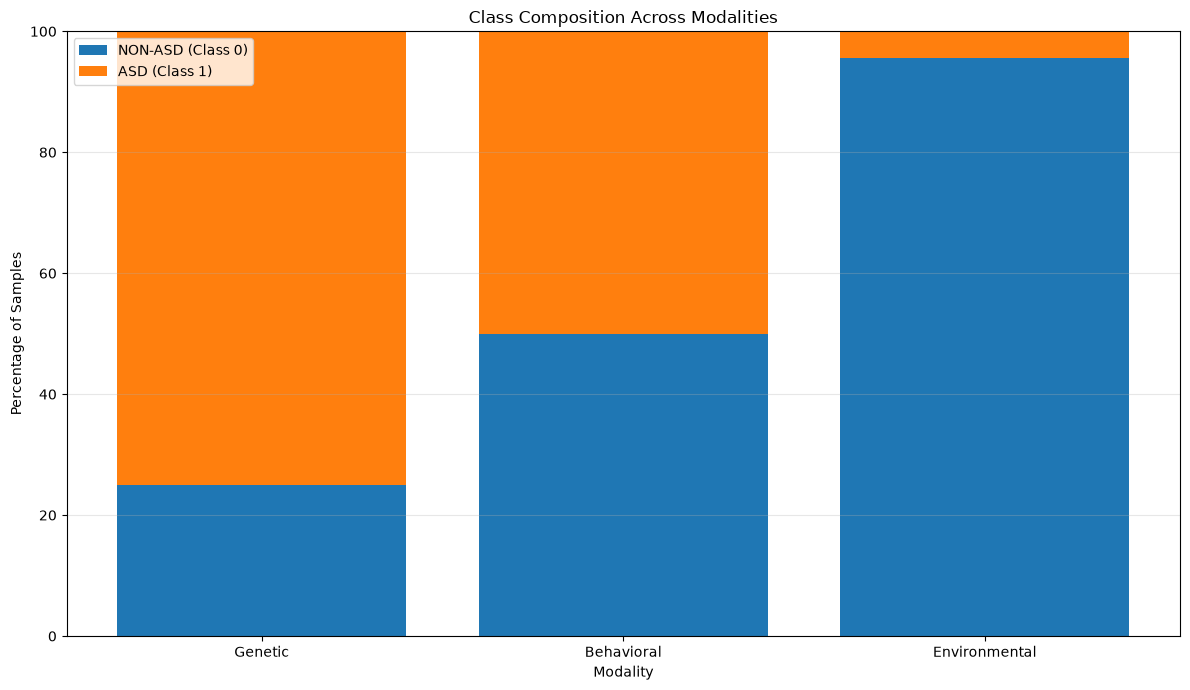


Figure saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_09_class_percentage_distribution.png


In [10]:
# ============================================================
# CELL 8 — CLASS PERCENTAGE DISTRIBUTION VISUALIZATION
# ============================================================

print("=" * 100)
print("GENERATING CLASS PERCENTAGE DISTRIBUTION")
print("=" * 100)

non_asd_percentages = distribution_df[
    "NON-ASD Percentage"
].tolist()

asd_percentages = distribution_df[
    "ASD Percentage"
].tolist()

x = np.arange(len(modalities))

plt.figure(figsize=(12, 7))

plt.bar(
    x,
    non_asd_percentages,
    label="NON-ASD (Class 0)"
)

plt.bar(
    x,
    asd_percentages,
    bottom=non_asd_percentages,
    label="ASD (Class 1)"
)

plt.xticks(x, modalities)

plt.xlabel("Modality")
plt.ylabel("Percentage of Samples")

plt.title(
    "Class Composition Across Modalities"
)

plt.ylim(0, 100)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

percentage_distribution_figure = (
    FIGURE_DIR
    / "01_09_class_percentage_distribution.png"
)

plt.savefig(
    percentage_distribution_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved:")
print(percentage_distribution_figure)

In [11]:
# ============================================================
# CELL 9 — VALIDATE CROSS-MODAL BALANCED SAMPLING STRATEGY
# ============================================================

print("=" * 100)
print("CROSS-MODAL BALANCED SAMPLING VALIDATION")
print("=" * 100)

# ------------------------------------------------------------
# Sampling configuration used in PCA, t-SNE, and UMAP
# ------------------------------------------------------------

balanced_sample_size = 116

sampling_validation = []

for modality, labels in labels_dict.items():

    original_size = len(labels)

    sampling_validation.append({
        "Modality": modality,
        "Original Sample Count": original_size,
        "Cross-Modal Sample Count": balanced_sample_size,
        "Original Class 0": int(np.sum(labels == 0)),
        "Original Class 1": int(np.sum(labels == 1)),
        "Purpose": (
            "Reference modality"
            if modality == "Genetic"
            else "Sampled for equal modality representation"
        )
    })

sampling_validation_df = pd.DataFrame(
    sampling_validation
)

print("\nBALANCED CROSS-MODAL SAMPLING STRATEGY\n")
print(sampling_validation_df.to_string(index=False))

sampling_validation_path = (
    REPORT_DIR
    / "01_09_cross_modal_sampling_validation.csv"
)

sampling_validation_df.to_csv(
    sampling_validation_path,
    index=False
)

print("\n✓ Cross-modal sampling strategy documented")

CROSS-MODAL BALANCED SAMPLING VALIDATION

BALANCED CROSS-MODAL SAMPLING STRATEGY

     Modality  Original Sample Count  Cross-Modal Sample Count  Original Class 0  Original Class 1                                   Purpose
      Genetic                    116                       116                29                87                        Reference modality
   Behavioral                    880                       116               439               441 Sampled for equal modality representation
Environmental                  47768                       116             45650              2118 Sampled for equal modality representation

✓ Cross-modal sampling strategy documented


In [12]:
# ============================================================
# CELL 10 — FINAL DISTRIBUTION VALIDATION CONCLUSION
# ============================================================

print("=" * 100)
print("STEP 01.9 — FINAL LABEL AND CLASS DISTRIBUTION SUMMARY")
print("=" * 100)

print("\nCLASS DISTRIBUTION\n")

for _, row in distribution_df.iterrows():

    print(f"{row['Modality']}")
    print(
        f"  Total samples : {row['Total Samples']}"
    )
    print(
        f"  NON-ASD       : "
        f"{row['NON-ASD Count (Class 0)']} "
        f"({row['NON-ASD Percentage']}%)"
    )
    print(
        f"  ASD           : "
        f"{row['ASD Count (Class 1)']} "
        f"({row['ASD Percentage']}%)"
    )
    print()

print("=" * 100)
print("IMBALANCE ASSESSMENT")
print("=" * 100)

for _, row in imbalance_df.iterrows():

    print(f"\n{row['Modality']}")
    print(
        f"  Imbalance ratio : "
        f"{row['Imbalance Ratio']}"
    )
    print(
        f"  Severity        : "
        f"{row['Imbalance Severity']}"
    )

print("\n" + "=" * 100)
print("METHODOLOGICAL CONCLUSION")
print("=" * 100)

print("""
The three modalities exhibit substantially different original
dataset sizes and class distributions.

Therefore, direct analysis using all available samples could cause
large modalities or dominant classes to disproportionately influence
cross-modal representation comparisons.

Balanced modality sampling is therefore justified for visualization
and comparative knowledge-level analysis.

Important distinction:

The balancing procedure ensures fair modality representation.

It does NOT establish patient-level correspondence.

No individual patient identity is shared or assumed across Genetic,
Behavioral, and Environmental modalities.

All analyses remain knowledge-level and class-level comparisons
between independently learned representations.
""")

print("=" * 100)
print("✓ STEP 01.9 COMPLETED")
print("✓ LABEL INTEGRITY VALIDATED")
print("✓ CLASS DISTRIBUTIONS DOCUMENTED")
print("✓ CLASS IMBALANCE QUANTIFIED")
print("✓ BALANCED SAMPLING STRATEGY JUSTIFIED")
print("✓ NO PATIENT-LEVEL ASSUMPTIONS MADE")
print("=" * 100)

print("\nGenerated Reports:")
print("1. 01_09_label_integrity_validation.csv")
print("2. 01_09_class_distribution_summary.csv")
print("3. 01_09_class_imbalance_metrics.csv")
print("4. 01_09_cross_modal_sampling_validation.csv")

print("\nGenerated Figures:")
print("1. 01_09_raw_class_distribution.png")
print("2. 01_09_class_percentage_distribution.png")

print("\nNext Logical Step:")
print("01.10 — Embedding Compatibility Conclusion")

STEP 01.9 — FINAL LABEL AND CLASS DISTRIBUTION SUMMARY

CLASS DISTRIBUTION

Genetic
  Total samples : 116
  NON-ASD       : 29 (25.0%)
  ASD           : 87 (75.0%)

Behavioral
  Total samples : 880
  NON-ASD       : 439 (49.89%)
  ASD           : 441 (50.11%)

Environmental
  Total samples : 47768
  NON-ASD       : 45650 (95.57%)
  ASD           : 2118 (4.43%)

IMBALANCE ASSESSMENT

Genetic
  Imbalance ratio : 3.0
  Severity        : Moderate Imbalance

Behavioral
  Imbalance ratio : 1.0046
  Severity        : Balanced

Environmental
  Imbalance ratio : 21.5534
  Severity        : Extreme Imbalance

METHODOLOGICAL CONCLUSION

The three modalities exhibit substantially different original
dataset sizes and class distributions.

Therefore, direct analysis using all available samples could cause
large modalities or dominant classes to disproportionately influence
cross-modal representation comparisons.

Balanced modality sampling is therefore justified for visualization
and comparative kno